In [1]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv("Dataset-Coginifiyz.csv",encoding='utf-8-sig')
df.head(1)

,ï»¿Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365


In [14]:
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
c=df.copy()
c['Cuisines']=c['Cuisines'].fillna('Unknown')
c['Main']=c['Cuisines'].str.split(",").str[0].str.strip()
c=c[c['Main']!="Unknown"]

top=c['Main'].value_counts().head(10).index
c=c[c['Main'].isin(top)]
c['Main'].value_counts()

Main
North Indian    2992
Chinese          855
Fast Food        672
Bakery           621
Cafe             617
American         278
South Indian     262
Mithai           246
Street Food      236
Continental      235
Name: count, dtype: int64

In [5]:
feat = c[["City", "Price range", "Average Cost for two", "Aggregate rating",
          "Votes", "Has Table booking", "Has Online delivery",
          "Latitude", "Longitude"]].copy()

for col in ["Has Table booking", "Has Online delivery"]:
    feat[col] = feat[col].map({"Yes": 1, "No": 0})

feat = pd.get_dummies(feat, columns=["City"], drop_first=True)
yc = c["Main"]

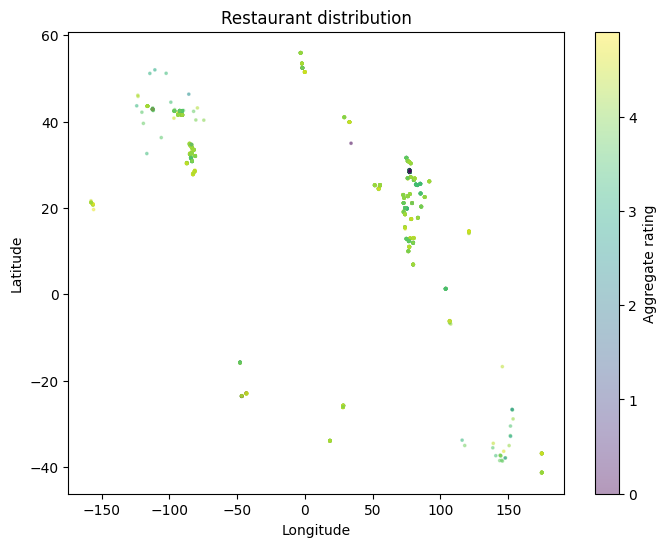

In [6]:
g = df[(df["Latitude"] != 0) & (df["Longitude"] != 0)].copy()

plt.figure(figsize=(8, 6))
plt.scatter(g["Longitude"], g["Latitude"], s=3, alpha=0.4,
            c=g["Aggregate rating"], cmap="viridis")
plt.colorbar(label="Aggregate rating")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Restaurant distribution"); plt.show()

In [12]:
import plotly.express as px
s = g.sample(1000, random_state=42)
fig = px.scatter_geo(s, lat="Latitude", lon="Longitude",
                     hover_name="Restaurant Name", color="Aggregate rating")
fig.show()

In [ ]:
city_cnt = df["City"].value_counts()
city_cnt.head(10).plot(kind="bar", title="Top 10 cities by restaurant count")

In [ ]:
city_stats = df.groupby("City").agg(
    restaurants=("Restaurant ID", "count"),
    avg_rating=("Aggregate rating", "mean"),
    avg_cost=("Average Cost for two", "mean"),
    avg_price_range=("Price range", "mean"),
).round(2)
city_stats[city_stats["restaurants"] >= 20].sort_values("avg_rating", ascending=False).head(10)

In [ ]:
tmp = df.dropna(subset=["Cuisines"]).copy()
tmp["Main"] = tmp["Cuisines"].str.split(",").str[0].str.strip()
top_cuisine = tmp.groupby("City")["Main"].agg(lambda x: x.value_counts().index[0])
top_cuisine[city_cnt.head(10).index]

In [ ]:
delhi = df[df["City"] == "New Delhi"]
delhi.groupby("Locality").agg(
    restaurants=("Restaurant ID", "count"),
    avg_rating=("Aggregate rating", "mean")
).query("restaurants >= 15").sort_values("avg_rating", ascending=False).head(10).round(2)

In [ ]:
def city_summary(city):
    x = df[df["City"] == city]
    if x.empty:
        return "City nahi mili, spelling check karo"
    top_c = (x["Cuisines"].dropna().str.split(",").str[0].str.strip()
               .value_counts().head(3).to_dict())
    return {
        "restaurants": len(x),
        "avg_rating": round(x["Aggregate rating"].mean(), 2),
        "avg_cost_for_two": round(x["Average Cost for two"].mean(), 1),
        "top_cuisines": top_c,
    }

In [ ]:
def nearby(lat, lon, top_n=5):
    g2 = g.copy()   # g = Cell 26 wala clean data (lat/long != 0)
    g2["dist"] = np.sqrt((g2["Latitude"] - lat)**2 + (g2["Longitude"] - lon)**2)
    return g2.sort_values("dist").head(top_n)[
        ["Restaurant Name", "City", "Cuisines", "Aggregate rating", "Price range"]]

In [ ]:
print(city_summary("New Delhi"))
nearby(28.63, 77.21)